# Пример 1. Классификация отзывов к фильмам (бинарная классификация)

In [1]:
# from tensorflow import keras
# from tensorflow.keras.datasets import imdb
# from tensorflow.keras import layers
import keras
from keras import layers
# from keras.datasets import imdb
import numpy as np
import matplotlib.pyplot as plt

2025-02-20 15:29:55.353555: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-02-20 15:29:55.353604: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-02-20 15:29:55.354574: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-02-20 15:29:55.358652: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# Загрузка набора данных IMDB
(train_data, train_labels), (test_data, test_labels) = imdb.load_data(
    num_words=10_000
)

In [3]:
## Декодирование отзыва в текст
"""
word_index = imdb.get_word_index()
reverse_word_index = {value: key for (key, value) in word_index.items()}
decoded_review = " ".join(
    [reverse_word_index.get(i-3, "?") for i in train_data[0]])    # вернуть значение по ключу i-3 (смещение на 3 номера)
decoded_review                                                    # если ключа нет, вернуть "?"
"""

'\nword_index = imdb.get_word_index()\nreverse_word_index = {value: key for (key, value) in word_index.items()}\ndecoded_review = " ".join(\n    [reverse_word_index.get(i-3, "?") for i in train_data[0]])    # вернуть значение по ключу i-3 (смещение на 3 номера)\ndecoded_review                                                    # если ключа нет, вернуть "?"\n'

In [6]:
## Кодирование последовательности целых чисел в бинарную матрицу (маска целых чисел)
def vectorize_sequences(sequences, dimension=10_000):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        for j in sequence:        # j равен целому числу из последовательности
            results[i, j] = 1.    # запись единицы по номеру j -> маска целых чисел
    return results


In [ ]:
x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)
y_train = np.asarray(train_labels).astype("float32")
y_test = np.asarray(test_labels).astype("float32")

In [5]:
# Создание проверочного набора
x_val = x_train[:10_000]
partial_x_train = x_train[10_000:]
y_val = y_train[:10_000]
partial_y_train = y_train[10_000:]

In [6]:
# Определение модели
model = keras.Sequential([layers.Dense(16, activation="relu"),
                          layers.Dense(16, activation="relu"),
                          layers.Dense(1, activation="sigmoid")])
# Компиляция модели
model.compile(optimizer="rmsprop",
              loss="binary_crossentropy",
              # loss="mse",
              metrics=["accuracy"])
# Обучение модели
history = model.fit(partial_x_train,
                    partial_y_train,
                    epochs=20,
                    batch_size=512,
                    validation_data=(x_val, y_val))

2025-02-16 23:39:14.955596: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:26:00.0/numa_node
Your kernel may have been built without NUMA support.
2025-02-16 23:39:15.164931: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:26:00.0/numa_node
Your kernel may have been built without NUMA support.
2025-02-16 23:39:15.164989: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:26:00.0/numa_node
Your kernel may have been built without NUMA support.
2025-02-16 23:39:15.166902: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:26:00.0/numa_node
Your kernel may have been built without NUMA support.
2025-02-16 23:39:15.166949: I external/local_xla/xla/stream_executor

Epoch 1/20


I0000 00:00:1739738356.574709   10560 service.cc:145] XLA service 0x7f71f8103bc0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1739738356.574756   10560 service.cc:153]   StreamExecutor device (0): NVIDIA GeForce GTX 1660 SUPER, Compute Capability 7.5
2025-02-16 23:39:16.633701: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2025-02-16 23:39:16.789459: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8907


21/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6568 - loss: 0.6377

I0000 00:00:1739738357.475162   10560 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.6901 - loss: 0.6110 - val_accuracy: 0.8577 - val_loss: 0.4122
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8858 - loss: 0.3557 - val_accuracy: 0.8787 - val_loss: 0.3242
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9202 - loss: 0.2504 - val_accuracy: 0.8874 - val_loss: 0.2860
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9362 - loss: 0.2015 - val_accuracy: 0.8837 - val_loss: 0.2872
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9455 - loss: 0.1657 - val_accuracy: 0.8873 - val_loss: 0.2765
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9596 - loss: 0.1342 - val_accuracy: 0.8798 - val_loss: 0.3139
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9635 - loss: 0.1210 - val_accuracy: 0.8839 - val_loss: 0.2947
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9701 - loss: 0.0985 - val_accuracy: 0.8840 - val_loss: 0.31

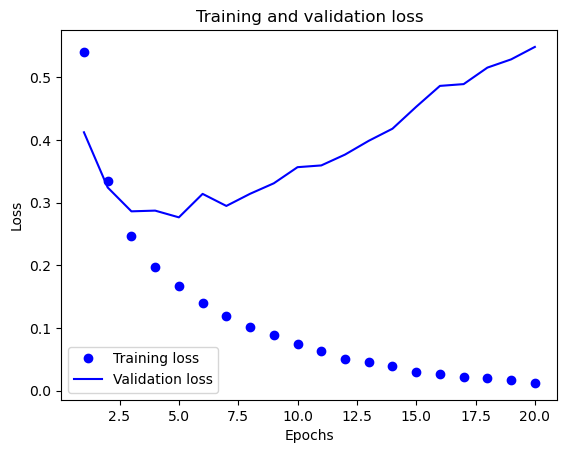

In [7]:
# Формирование графиков потерь на этапах обучения и проверки
history_dict = history.history
loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]
epochs = range(1, len(loss_values) + 1)
plt.plot(epochs, loss_values, "bo", label="Training loss")
plt.plot(epochs, val_loss_values, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()


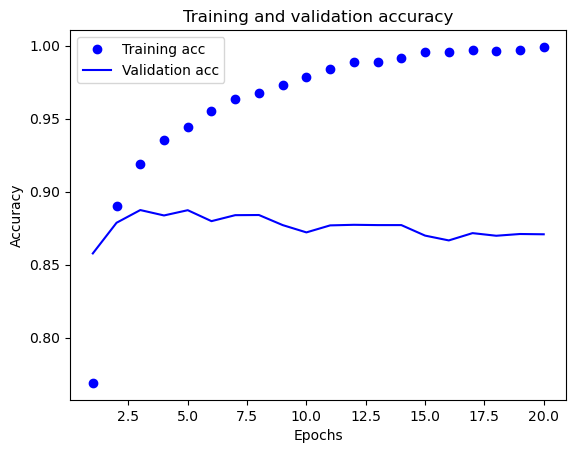

In [8]:
# Формирование графиков точности на этапах обучения и проверки
plt.clf()
acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]
plt.plot(epochs, acc, "bo", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [9]:
# Обучение модели с нуля
model = keras.Sequential([layers.Dense(16, activation="relu"),
                          layers.Dense(16, activation="relu"),
                          layers.Dense(1, activation="sigmoid")])
model.compile(optimizer="rmsprop",
              loss="binary_crossentropy",
              metrics=["accuracy"])
model.fit(x_train, y_train, epochs=4, batch_size=512)
results = model.evaluate(x_test, y_test)
print(f"Потери на контрольной выборке {(results[0] * 100):.3f}%")
print(f"Точность на контрольной выборке {(results[1] * 100):.3f}%")

Epoch 1/4
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.7300 - loss: 0.5594  
Epoch 2/4
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9015 - loss: 0.2891 
Epoch 3/4
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9246 - loss: 0.2144 
Epoch 4/4
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9384 - loss: 0.1788 
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8859 - loss: 0.2857
Потери на контрольной выборке 28.462%
Точность на контрольной выборке 88.716%


# Пример 2. Классификация новостных лент (однозначная многоклассовая классификация)

In [5]:
from keras.datasets import reuters


In [6]:
(train_data, train_labels), (test_data, test_labels) = reuters.load_data(
    num_words = 10_000
)


In [ ]:
## Декодирование новости
"""
word_index = reuters.get_word_index()
reverse_word_index = {word_index[word]: word for word in word_index}
decoded_news = " ".join([reverse_word_index.get(i-3, "?") for i in train_data[5]])
decoded_news
"""

In [7]:
x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)

In [8]:
def to_one_hot(labels, dimms=46):
    result = np.zeros((len(labels), dimms))
    for i, label in enumerate(labels):
        result[i, label] = 1
    return result


y_train = to_one_hot(train_labels)
y_test = to_one_hot(test_labels)


In [9]:
model = keras.Sequential([layers.Dense(64, activation="relu"),
                          layers.Dense(64, activation="relu"),
                          layers.Dense(46, activation="softmax")])
model.compile(optimizer="rmsprop",
              loss="categorical_crossentropy",
              metrics=["accuracy"])


2025-02-17 00:04:06.467676: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:26:00.0/numa_node
Your kernel may have been built without NUMA support.
2025-02-17 00:04:06.663975: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:26:00.0/numa_node
Your kernel may have been built without NUMA support.
2025-02-17 00:04:06.664034: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:26:00.0/numa_node
Your kernel may have been built without NUMA support.
2025-02-17 00:04:06.666442: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:26:00.0/numa_node
Your kernel may have been built without NUMA support.
2025-02-17 00:04:06.666488: I external/local_xla/xla/stream_executor

In [10]:
x_val = x_train[:1000]
x_train_partial = x_train[1000:]
y_val = y_train[:1000]
y_train_partial = y_train[1000:]


In [11]:
history = model.fit(x_train_partial,
                    y_train_partial,
                    epochs=20,
                    batch_size=512,
                    validation_data=(x_val, y_val))


Epoch 1/20


I0000 00:00:1739739858.741424   13492 service.cc:145] XLA service 0x7fa61c11a0f0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1739739858.741877   13492 service.cc:153]   StreamExecutor device (0): NVIDIA GeForce GTX 1660 SUPER, Compute Capability 7.5
2025-02-17 00:04:18.806897: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2025-02-17 00:04:18.948506: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8907


11/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3427 - loss: 3.4424

I0000 00:00:1739739860.150236   13492 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step - accuracy: 0.3998 - loss: 3.2168 - val_accuracy: 0.6340 - val_loss: 1.8370
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6733 - loss: 1.6371 - val_accuracy: 0.6800 - val_loss: 1.4097
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7342 - loss: 1.2362 - val_accuracy: 0.7360 - val_loss: 1.2264
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7879 - loss: 1.0163 - val_accuracy: 0.7660 - val_loss: 1.1203
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8253 - loss: 0.8343 - val_accuracy: 0.7880 - val_loss: 1.0438
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8485 - loss: 0.6948 - val_accuracy: 0.7850 - val_loss: 1.0123
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8738 - loss: 0.5792 - val_accuracy: 0.8110 - val_loss: 0.9474
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8976 - loss: 0.4798 - val_accuracy: 0.8020 - val_loss: 0.9401
Ep

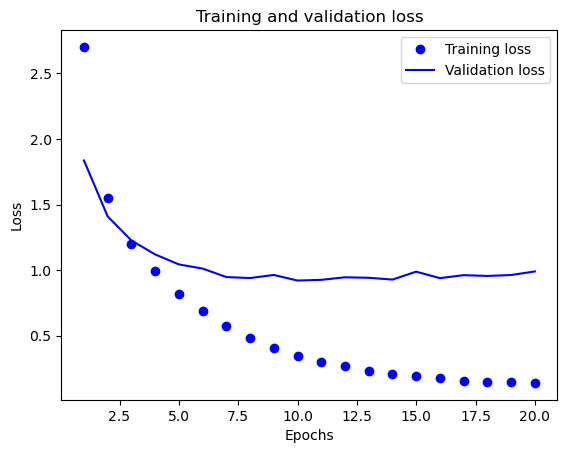

In [14]:
# Формирование графиков потерь на этапах обучения и проверки
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(val_loss) + 1)
plt.plot(epochs, loss, "bo", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()


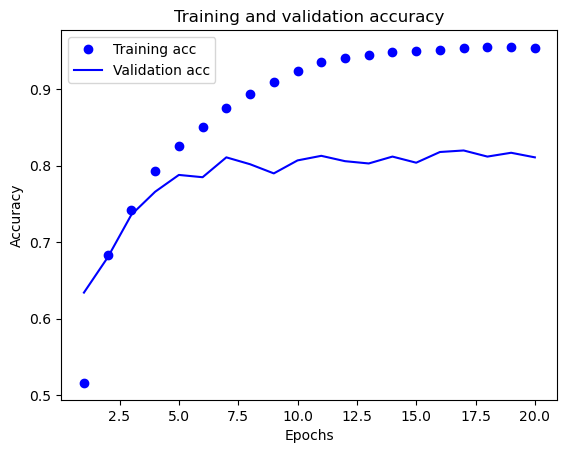

In [15]:
# Формирование графиков точности на этапах обучения и проверки
plt.clf()
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
plt.plot(epochs, acc, "bo", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


In [16]:
# Обучение модели с нуля
model = keras.Sequential([layers.Dense(64, activation="relu"),
                          layers.Dense(64, activation="relu"),
                          layers.Dense(46, activation="softmax")])
model.compile(optimizer="rmsprop",
              loss="categorical_crossentropy",
              metrics=["accuracy"])
model.fit(x_train, y_train, epochs=9, batch_size=512)
results = model.evaluate(x_test, y_test)
print(f"Потери на контрольной выборке {(results[0] * 100):.3f}%")
print(f"Точность на контрольной выборке {(results[1] * 100):.3f}%")


Epoch 1/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - accuracy: 0.4026 - loss: 3.0639  
Epoch 2/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6838 - loss: 1.4870 
Epoch 3/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7523 - loss: 1.1228 
Epoch 4/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8096 - loss: 0.9069 
Epoch 5/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8452 - loss: 0.7240 
Epoch 6/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8689 - loss: 0.6068 
Epoch 7/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8952 - loss: 0.5007 
Epoch 8/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9138 - loss: 0.4102 
Epoch 9/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9228 - loss: 0.3549 
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7962 - loss: 0.8962   
Потери на контрольной выборке 94.430%
Точность на контрольной выборке 78.940%


In [17]:
import copy


test_labels_copy = copy.copy(test_labels)
np.random.shuffle(test_labels_copy)
hits_array = np.array(test_labels) == np.array(test_labels_copy)
hits_array.mean()


0.17764915405164738

In [22]:
prediction = model.predict(x_test)
# for i in range(len(prediction)):
#     print(f"{prediction[i]}\t{y_test[i]}")


71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


In [7]:
## Преобразовние меток в тензоры целых чисел
y_train = np.array(train_labels)
y_test = np.array(test_labels)

In [8]:
y_train

array([ 3,  4,  3, ..., 25,  3, 25])

In [ ]:
x_val = x_train[:1000]
x_train_partial = x_train[1000:]
y_val = y_train[:1000]
y_train_partial = y_train[1000:]
new_model = keras.Sequential([layers.Dense(64, activation="relu"),
                              layers.Dense( 4, activation="relu"),
                              layers.Dense(46, activation="softmax")])
new_model.compile(optimizer="rmsprop",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
new_history = new_model.fit(x_train_partial,
                            y_train_partial,
                            epochs=20,
                            batch_size=128,
                            validation_data=(x_val, y_val))

Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.0933 - loss: 3.5771 - val_accuracy: 0.2220 - val_loss: 2.7493
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3249 - loss: 2.4744 - val_accuracy: 0.5960 - val_loss: 1.8345
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6254 - loss: 1.6710 - val_accuracy: 0.6120 - val_loss: 1.6233
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6559 - loss: 1.4464 - val_accuracy: 0.6370 - val_loss: 1.5173
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6637 - loss: 1.3470 - val_accuracy: 0.6580 - val_loss: 1.4609
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7001 - loss: 1.2101 - val_accuracy: 0.6530 - val_loss: 1.4131
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7018 - loss: 1.1099 - val_accuracy: 0.6620 - val_loss: 1.3949
Epoch 8/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7211 - loss: 1.0139 - val_accuracy: 0.6840 - val_loss

In [19]:
results = new_model.evaluate(x_test, y_test)
print(f"Потери на контрольной выборке {(results[0] * 100):.3f}%")
print(f"Точность на контрольной выборке {(results[1] * 100):.3f}%")


71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7108 - loss: 1.7314   
Потери на контрольной выборке 173.794%
Точность на контрольной выборке 70.125%


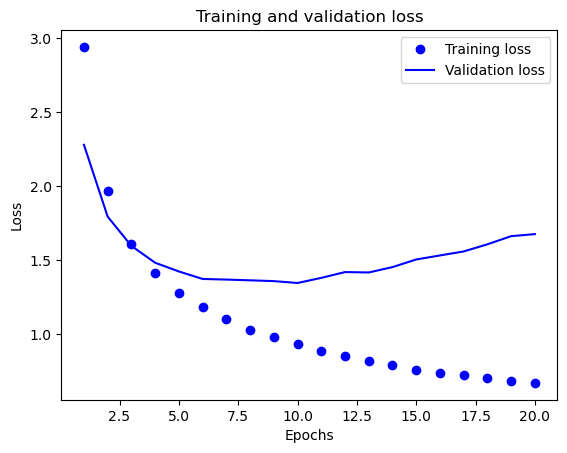

In [24]:
# Формирование графиков потерь на этапах обучения и проверки
loss = new_history.history["loss"]
val_loss = new_history.history["val_loss"]
epochs = range(1, len(loss_values) + 1)
plt.plot(epochs, loss, "bo", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()


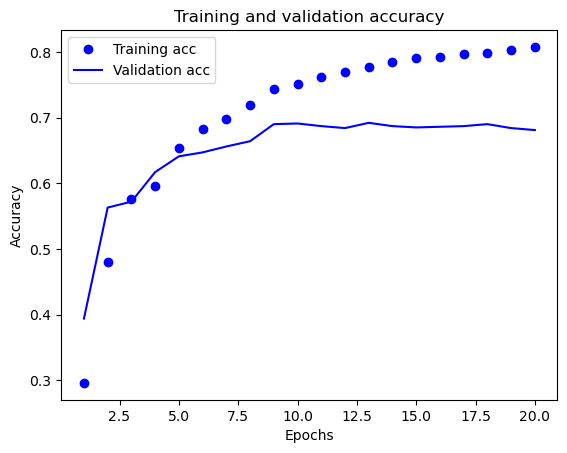

In [25]:
# Формирование графиков точности на этапах обучения и проверки
plt.clf()
acc = new_history.history["accuracy"]
val_acc = new_history.history["val_accuracy"]
plt.plot(epochs, acc, "bo", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


# Пример 3. Предсказание цен на дома (регрессия)

In [1]:
from keras.datasets import boston_housing


2025-02-24 00:48:33.486556: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-02-24 00:48:33.486606: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-02-24 00:48:33.487677: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-02-24 00:48:33.492121: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
(train_data, train_targets), (test_data, test_targets) = boston_housing.load_data()

In [4]:
len(train_data)

404

In [3]:
mean = train_data.mean(axis=0)
std = train_data.std(axis=0)
train_data -= mean
train_data /= std
test_data -= mean
test_data /= std


In [7]:
mean, std

(array([3.74511057e+00, 1.14801980e+01, 1.11044307e+01, 6.18811881e-02,
        5.57355941e-01, 6.26708168e+00, 6.90106436e+01, 3.74027079e+00,
        9.44059406e+00, 4.05898515e+02, 1.84759901e+01, 3.54783168e+02,
        1.27408168e+01]),
 array([9.22929073e+00, 2.37382770e+01, 6.80287253e+00, 2.40939633e-01,
        1.17147847e-01, 7.08908627e-01, 2.79060634e+01, 2.02770050e+00,
        8.68758849e+00, 1.66168506e+02, 2.19765689e+00, 9.39946015e+01,
        7.24556085e+00]))

In [29]:
def build_model():
    model = keras.Sequential([layers.Dense(64, activation="relu"),
                              layers.Dense(64, activation="relu"),
                              layers.Dense(1)])
    model.compile(optimizer="rmsprop", loss="mse", metrics=["mae"])
    return model

In [34]:
k = 4
num_of_val_samples = len(train_data) // k
num_of_epochs = 100
all_scores = []
for i in range(k):
    print(f"Processing fold #{i}")
    val_data = train_data[i*num_of_val_samples:(i+1)*num_of_val_samples]
    val_targets = train_targets[i*num_of_val_samples:(i+1)*num_of_val_samples]
    train_data_partial = np.concatenate(
        [
            train_data[:i*num_of_val_samples],
            train_data[(i+1)*num_of_val_samples:]
        ]
    )
    train_targets_partial = np.concatenate(
        [
            train_targets[:i*num_of_val_samples],
            train_targets[(i+1)*num_of_val_samples:]
        ]
    )
    model = build_model()
    model.fit(train_data_partial,
              train_targets_partial,
              epochs=num_of_epochs,
              batch_size=16,
              verbose=0)
    val_mse, val_mae = model.evaluate(val_data, val_targets, verbose=0)
    all_scores.append(val_mae)
print(all_scores)
print(np.mean(all_scores))


Processing fold #0
Processing fold #1
Processing fold #2
Processing fold #3
[1.9378982782363892, 2.434987783432007, 2.411938190460205, 2.2814910411834717]
2.266578823328018


In [36]:
num_of_epochs = 500
all_mae_histories = []
for i in range(k):
    print(f"Processing fold #{i}")
    val_data = train_data[i*num_of_val_samples:(i+1)*num_of_val_samples]
    val_targets = train_targets[i*num_of_val_samples:(i+1)*num_of_val_samples]
    train_data_partial = np.concatenate(
        [
            train_data[:i*num_of_val_samples],
            train_data[(i+1)*num_of_val_samples:]
        ]
    )
    train_targets_partial = np.concatenate(
        [
            train_targets[:i*num_of_val_samples],
            train_targets[(i+1)*num_of_val_samples:]
        ]
    )
    model = build_model()
    history = model.fit(train_data_partial,
                        train_targets_partial,
                        epochs=num_of_epochs,
                        batch_size=16,
                        validation_data=(val_data, val_targets),
                        verbose=0)
    mae_history = history.history["val_mae"]
    all_mae_histories.append(mae_history)


Processing fold #0
Processing fold #1
Processing fold #2
Processing fold #3


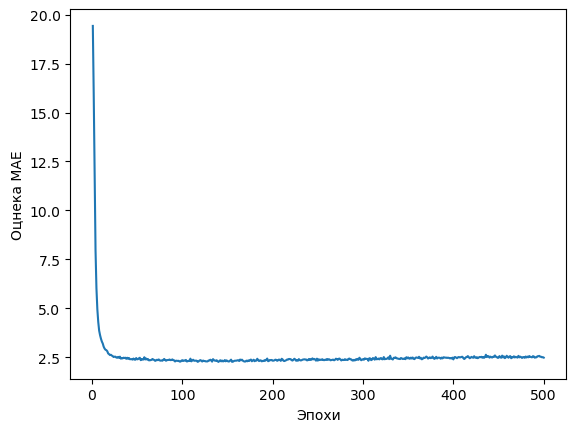

In [44]:
average_mae_history = [
    np.mean([x[i] for x in all_mae_histories]) for i in range(num_of_epochs)
]
plt.plot(range(1, num_of_epochs+1), average_mae_history)
plt.xlabel("Эпохи")
plt.ylabel("Оцнека MAE")
plt.show()


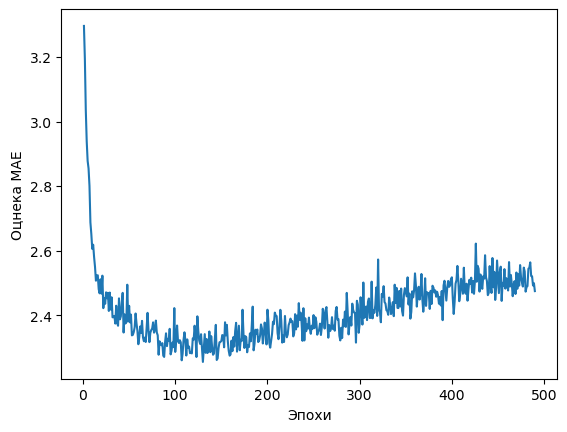

In [45]:
truncated_mae_history = average_mae_history[10:]
plt.plot(range(1, len(truncated_mae_history)+1), truncated_mae_history)
plt.xlabel("Эпохи")
plt.ylabel("Оцнека MAE")
plt.show()


In [49]:
new_model = build_model()
new_model.fit(train_data, train_targets, epochs=110, batch_size=16, verbose=0)
test_mse_score, test_mae_score = new_model.evaluate(test_data, test_targets)
test_mae_score

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 15.8092 - mae: 2.2628


2.4399051666259766

In [50]:
predictions = new_model.predict(test_data)
predictions[0]


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step 


array([8.639124], dtype=float32)